# **Task 1**

In [1]:

!pip install "transformers>=4.40,<5" torch matplotlib numpy


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 68.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 8.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 55.2 MB/s  0:00:00
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 1.33.0
    Uninstalling huggingface_hub-1.33.0:
      Successfully uninstalled huggingface_hub-1.33.0
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.23.3
    Uninstalling tokenizers-0.23.3:
      Successfully uninstalled tokenizers-0.23.3
  Attempting uninstall: transformers
    Found existing installation: transformers 5.22.1
    Uninstalling transformers-5.22.1:
      Successfully uninstalled transformers-5.22.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [transformers]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency confl

In [2]:

import torch
import numpy as np
import matplotlib.pyplot as plt
from transformers import GPT2LMHeadModel

# Hugging Face üzerinden eğitilmiş GPT-2'yi yükle
model = GPT2LMHeadModel.from_pretrained("gpt2")

# Modeli evaluation moduna al
model.eval()

print("GPT-2 başarıyla yüklendi!")
print(model.config)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT-2 başarıyla yüklendi!
GPT2Config {
  "activation_function": "gelu_new",
  "architectures": [
    "GPT2LMHeadModel"
  ],
  "attn_pdrop": 0.1,
  "bos_token_id": 50256,
  "dtype": "float32",
  "embd_pdrop": 0.1,
  "eos_token_id": 50256,
  "initializer_range": 0.02,
  "layer_norm_epsilon": 1e-05,
  "model_type": "gpt2",
  "n_ctx": 1024,
  "n_embd": 768,
  "n_head": 12,
  "n_inner": null,
  "n_layer": 12,
  "n_positions": 1024,
  "reorder_and_upcast_attn": false,
  "resid_pdrop": 0.1,
  "scale_attn_by_inverse_layer_idx": false,
  "scale_attn_weights": true,
  "summary_activation": null,
  "summary_first_dropout": 0.1,
  "summary_proj_to_labels": true,
  "summary_type": "cls_index",
  "summary_use_proj": true,
  "task_specific_params": {
    "text-generation": {
      "do_sample": true,
      "max_length": 50
    }
  },
  "transformers_version": "4.57.6",
  "use_cache": true,
  "vocab_size": 50257
}



In [3]:

# Modelin ağırlıklarını al
state_dict = model.state_dict()

print("GPT-2 Ağırlık İsimleri ve Boyutları")
print("-" * 65)

for name, tensor in state_dict.items():
    print(f"{name:55s} {str(tuple(tensor.shape))}")


GPT-2 Ağırlık İsimleri ve Boyutları
-----------------------------------------------------------------
transformer.wte.weight                                  (50257, 768)
transformer.wpe.weight                                  (1024, 768)
transformer.h.0.ln_1.weight                             (768,)
transformer.h.0.ln_1.bias                               (768,)
transformer.h.0.attn.c_attn.weight                      (768, 2304)
transformer.h.0.attn.c_attn.bias                        (2304,)
transformer.h.0.attn.c_proj.weight                      (768, 768)
transformer.h.0.attn.c_proj.bias                        (768,)
transformer.h.0.ln_2.weight                             (768,)
transformer.h.0.ln_2.bias                               (768,)
transformer.h.0.mlp.c_fc.weight                         (768, 3072)
transformer.h.0.mlp.c_fc.bias                           (3072,)
transformer.h.0.mlp.c_proj.weight                       (3072, 768)
transformer.h.0.mlp.c_proj.bias                

In [4]:

total_params = sum(
    p.numel() for p in model.parameters()
)

# Eğitim sırasında güncellenebilen parametreler
trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Toplam parametre: {total_params:,}")
print(f"Eğitilebilir parametre: {trainable_params:,}")
print(f"Milyon cinsinden: {total_params / 1e6:.2f}M")


Toplam parametre: 124,439,808
Eğitilebilir parametre: 124,439,808
Milyon cinsinden: 124.44M


In [5]:

# Position embedding ağırlıklarını al
wpe = state_dict["transformer.wpe.weight"]

# PyTorch tensorunu NumPy dizisine çevir
wpe = wpe.detach().cpu().numpy()

print("WPE Shape:", wpe.shape)


WPE Shape: (1024, 768)


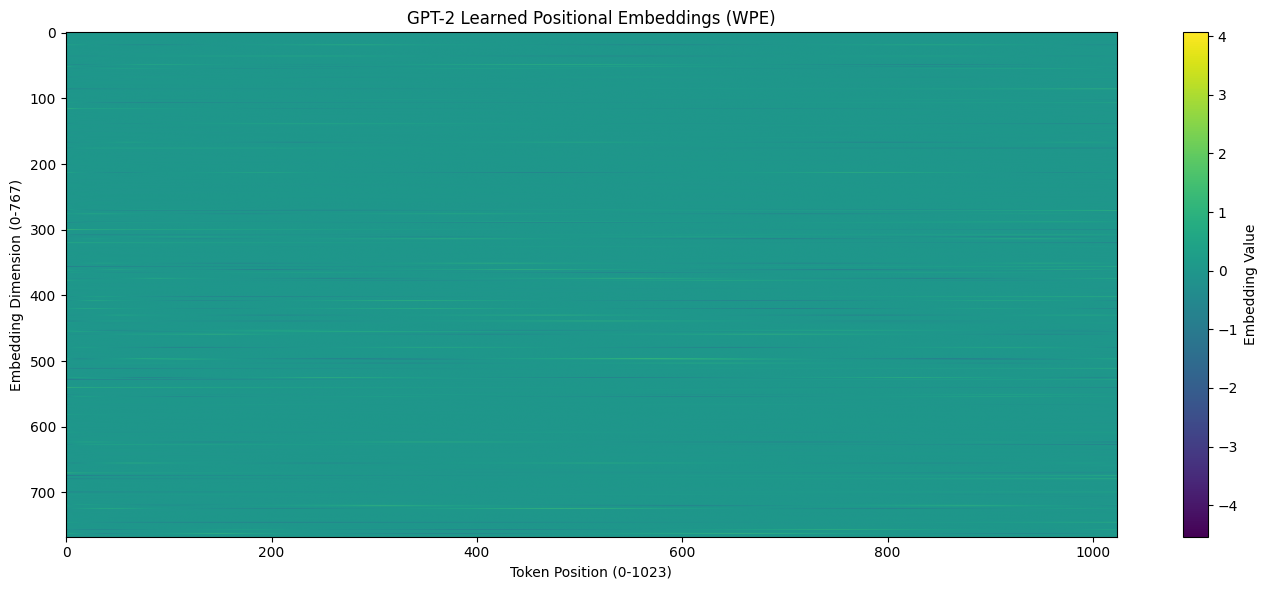

In [6]:

plt.figure(figsize=(14, 6))

plt.imshow(wpe.T, aspect="auto", cmap="viridis")
plt.colorbar(label="Embedding Value")

plt.xlabel("Token Position (0-1023)")
plt.ylabel("Embedding Dimension (0-767)")
plt.title("GPT-2 Learned Positional Embeddings (WPE)")

plt.tight_layout()
plt.show()


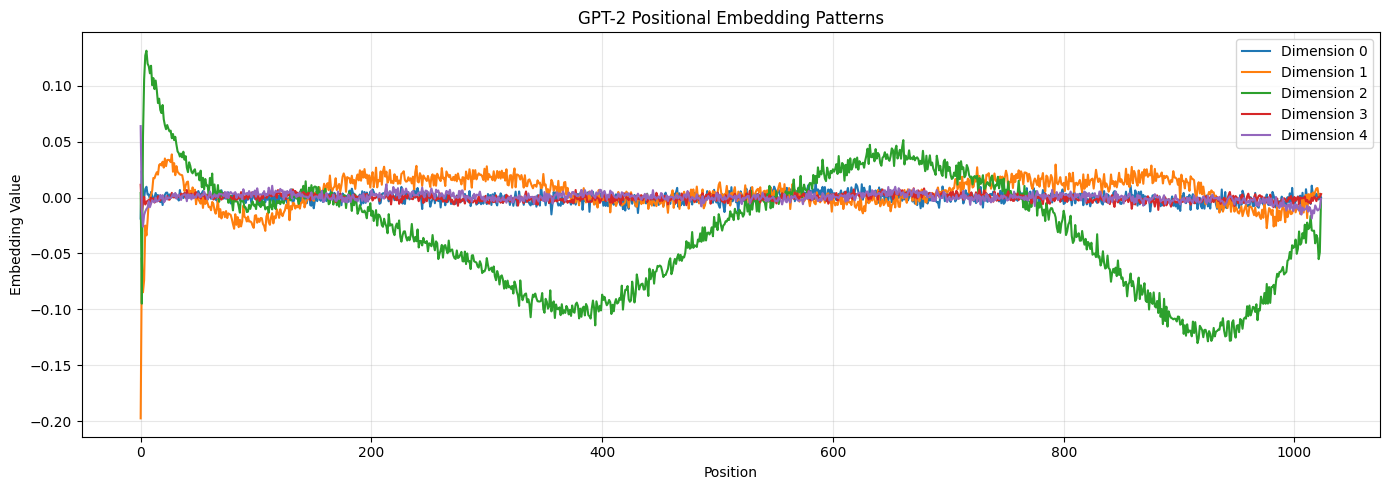

In [7]:

plt.figure(figsize=(14, 5))

# Seçilen embedding boyutları
dimensions = [0, 1, 2, 3, 4]

for dim in dimensions:
    plt.plot(
        wpe[:, dim],
        label=f"Dimension {dim}"
    )

plt.xlabel("Position")
plt.ylabel("Embedding Value")
plt.title("GPT-2 Positional Embedding Patterns")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## **Task 2**

In [8]:
%pip -q install 'transformers>=4.44,<5' torch

In [9]:
from dataclasses import dataclass
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257
    n_layer: int = 12
    n_head: int = 12
    n_embd: int = 768

In [10]:
class CausalSelfAttention(nn.Module):
    """Tum head'lerin Q, K, V projeksiyonlari tek Linear'da hesaplanir."""
    def __init__(self, config: GPTConfig):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.register_buffer(
            "mask",
            torch.tril(torch.ones(config.block_size, config.block_size, dtype=torch.bool))
            .view(1, 1, config.block_size, config.block_size),
            persistent=False,  # Hugging Face state_dict ile anahtar uyusmazligi yaratmaz
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:             #attention head e bölüyoruz
        B, T, C = x.shape
        hs = C // self.n_head
        q, k, v = self.c_attn(x).split(C, dim=2)  # (B,T,768) x 3
        q = q.view(B, T, self.n_head, hs).transpose(1, 2)
        k = k.view(B, T, self.n_head, hs).transpose(1, 2)
        v = v.view(B, T, self.n_head, hs).transpose(1, 2)

        scores = (q @ k.transpose(-2, -1)) / math.sqrt(hs)
        scores = scores.masked_fill(~self.mask[:, :, :T, :T], torch.finfo(scores.dtype).min)
        weights = F.softmax(scores, dim=-1)
        y = weights @ v
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.c_proj(y)

In [11]:
class MLP(nn.Module):
    def __init__(self, config: GPTConfig):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu = nn.GELU(approximate="tanh")  # GPT-2 gelu_new
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.c_proj(self.gelu(self.c_fc(x)))


class Block(nn.Module):
    def __init__(self, config: GPTConfig):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd, eps=1e-5)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd, eps=1e-5)
        self.mlp = MLP(config)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x + self.attn(self.ln_1(x))  # residual 1
        x = x + self.mlp(self.ln_2(x))    # residual 2
        return x

In [12]:
class GPT(nn.Module):
    def __init__(self, config: GPTConfig):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            wte=nn.Embedding(config.vocab_size, config.n_embd),
            wpe=nn.Embedding(config.block_size, config.n_embd),
            h=nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f=nn.LayerNorm(config.n_embd, eps=1e-5),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        # Weight tying: iki katman ayni Parameter nesnesini paylasir.
        self.lm_head.weight = self.transformer.wte.weight

    def forward(self, idx: torch.Tensor, targets: torch.Tensor | None = None):
        B, T = idx.shape
        assert T <= self.config.block_size, "Girdi 1024 token'dan uzun olamaz."
        pos = torch.arange(T, dtype=torch.long, device=idx.device)
        x = self.transformer.wte(idx) + self.transformer.wpe(pos)
        for block in self.transformer.h:
            x = block(x)  # Bloklar sirayla calisir.
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)  # (B, T, 50257)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

In [13]:
TRANSPOSE_SUFFIXES = (
    "attn.c_attn.weight",
    "attn.c_proj.weight",
    "mlp.c_fc.weight",
    "mlp.c_proj.weight",
)


def load_hf_weights(own_model: GPT, hf_model: nn.Module) -> int:
    src = hf_model.state_dict()
    dst = own_model.state_dict()
    # Farkli HF surumleri attention maskelerini buffer olarak kaydedebilir.
    src_keys = {k for k in src if not k.endswith(".attn.bias") and
                not k.endswith(".attn.masked_bias")}
    dst_keys = set(dst)
    if src_keys != dst_keys:
        raise KeyError(f"Eksik: {sorted(dst_keys-src_keys)}\nFazla: {sorted(src_keys-dst_keys)}")
    transposed_count = 0
    with torch.no_grad():
        for name in dst:
            weight = src[name]
            if name.endswith(TRANSPOSE_SUFFIXES):
                weight = weight.t()
                transposed_count += 1
            if dst[name].shape != weight.shape:
                raise RuntimeError(f"Shape uyusmazligi: {name}: {tuple(dst[name].shape)} vs {tuple(weight.shape)}")
            dst[name].copy_(weight)
    return transposed_count

In [14]:
from transformers import GPT2LMHeadModel, GPT2TokenizerFast

hf = GPT2LMHeadModel.from_pretrained("gpt2", attn_implementation="eager")
hf.eval()

own = GPT(GPTConfig())
transposed_count = load_hf_weights(own, hf)
own.eval()

total_params = sum(p.numel() for p in own.parameters())
print("Toplam tekil parametre:", f"{total_params:,}")
print("Transpoze edilen matris:", transposed_count)
print("Weight tying var mı?", own.lm_head.weight is own.transformer.wte.weight)
assert total_params == 124_439_808
assert transposed_count == 48

Toplam tekil parametre: 124,439,808
Transpoze edilen matris: 48
Weight tying var mı? True


In [15]:
tokenizer = GPT2TokenizerFast.from_pretrained("gpt2")
text = "The capital of France is"
idx = tokenizer(text, return_tensors="pt")["input_ids"]

with torch.inference_mode():
    hf_logits = hf(idx).logits
    own_logits, _ = own(idx)

abs_diff = (hf_logits - own_logits).abs()
print("Girdi:", text)
print("Token ID'leri:", idx.tolist())
print("HF logits shape:", tuple(hf_logits.shape))
print("Kendi logits shape:", tuple(own_logits.shape))
print(f"Maksimum mutlak fark: {abs_diff.max().item():.8f}")
print(f"Ortalama mutlak fark: {abs_diff.mean().item():.8f}")

same = torch.allclose(hf_logits, own_logits, rtol=1e-4, atol=1e-3)
print("Logits yaklaşık aynı mı?", same)
assert same, "Hata: logits tolerans içinde eşleşmedi!"
print("✅ BAŞARILI — Kendi GPT-2 ve Hugging Face logits değerleri eşleşiyor.")

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Girdi: The capital of France is
Token ID'leri: [[464, 3139, 286, 4881, 318]]
HF logits shape: (1, 5, 50257)
Kendi logits shape: (1, 5, 50257)
Maksimum mutlak fark: 0.00009537
Ortalama mutlak fark: 0.00002188
Logits yaklaşık aynı mı? True
✅ BAŞARILI — Kendi GPT-2 ve Hugging Face logits değerleri eşleşiyor.


In [16]:
hf_probs = torch.softmax(hf_logits[0, -1, :], dim=-1)
own_probs = torch.softmax(own_logits[0, -1, :], dim=-1)

_, top_ids = torch.topk(hf_probs, k=5)
print(f"Girdi: {text!r}")
print("Token               HF olasılık   Kendi model")
for token_id in top_ids.tolist():
    token = tokenizer.decode([token_id])
    print(f"{token!r:<19} {hf_probs[token_id].item():.6f}      {own_probs[token_id].item():.6f}")

Girdi: 'The capital of France is'
Token               HF olasılık   Kendi model
' the'              0.084591      0.084591
' now'              0.047947      0.047947
' a'                0.046160      0.046161
' France'           0.032378      0.032378
' Paris'            0.032245      0.032244


# **Task 3**

In [19]:

import torch
import torch.nn.functional as F
import tiktoken

# 1. Device Selection

device = "cpu"

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"

print("Device:", device)

# 2. Load Pretrained GPT-2

from transformers import GPT2LMHeadModel

model = GPT2LMHeadModel.from_pretrained("gpt2")
model.eval()
model.to(device)
model.eval()


torch.manual_seed(42)

# 3. Load Tokenizers

enc = tiktoken.get_encoding("gpt2")
enc_cl100k = tiktoken.get_encoding("cl100k_base")

# 4. Sampling Function

def generate_text(
    prompt,
    num_return_sequences=5,
    max_new_tokens=30,
    top_k=50
):

    tokens = enc.encode(prompt)

    tokens = torch.tensor(
        tokens, dtype=torch.long
    )

    tokens = tokens.unsqueeze(0).repeat(
        num_return_sequences, 1
    )

    x = tokens.to(device)

    # Generate new tokens

    for _ in range(max_new_tokens):

        with torch.no_grad():

            # Forward pass
            logits = model(x).logits

            # Support models returning (logits, loss)
            if isinstance(logits, tuple):
                logits = logits[0]

            # Last token position
            logits = logits[:, -1, :]

            # Convert logits to probabilities
            probs = F.softmax(logits, dim=-1)

            # Top-k sampling
            topk_probs, topk_indices = torch.topk(
                probs, top_k, dim=-1
            )

            # Sample from top-k probabilities
            ix = torch.multinomial(topk_probs, 1)

            # Get actual token ID
            xcol = torch.gather(
                topk_indices, -1, ix
            )

            # Append new token
            x = torch.cat((x, xcol), dim=1)

    # Decode generated sequences

    for i in range(num_return_sequences):

        generated_tokens = x[i].tolist()
        text = enc.decode(generated_tokens)

        print(f"\nSample {i + 1}:")
        print(text)


# 5. English Generation

english_prompt = "I want to learn artificial intelligence."

print("\n" + "=" * 60)
print("ENGLISH GENERATION")
print("=" * 60)

generate_text(english_prompt)


# 6. Turkish Generation

turkish_prompt = "Yapay zeka öğrenmek istiyorum."

print("\n" + "=" * 60)
print("TURKISH GENERATION")
print("=" * 60)

generate_text(turkish_prompt)


# 7. Tokenizer Analysis

print("\n" + "=" * 60)
print("TOKENIZER ANALYSIS")
print("=" * 60)

for language, prompt in [
    ("English", english_prompt),
    ("Turkish", turkish_prompt)
]:

    gpt2_tokens = enc.encode(prompt)
    cl100k_tokens = enc_cl100k.encode(prompt)

    print(f"\nLanguage: {language}")
    print(f"Text: {prompt}")

    print("GPT-2 Token Count:", len(gpt2_tokens))
    print("GPT-2 Token IDs:", gpt2_tokens)

    print("GPT-2 Token Pieces:")

    for token in gpt2_tokens:
        print(repr(enc.decode_single_token_bytes(token)))

    print("cl100k Token Count:", len(cl100k_tokens))


# 8. Turkish / English Token Ratio

gpt2_ratio = (
    len(enc.encode(turkish_prompt))
    / len(enc.encode(english_prompt))
)

cl100k_ratio = (
    len(enc_cl100k.encode(turkish_prompt))
    / len(enc_cl100k.encode(english_prompt))
)

print("\n" + "=" * 60)
print("TOKEN EFFICIENCY COMPARISON")
print("=" * 60)

print(f"GPT-2 Turkish/English Ratio: {gpt2_ratio:.2f}x")
print(f"cl100k Turkish/English Ratio: {cl100k_ratio:.2f}x")


Device: cpu

ENGLISH GENERATION

Sample 1:
I want to learn artificial intelligence. I want to learn how to make a robot. I wanted to spend years learning this.

And for many, being smart is hard.<|endoftext|>

Sample 2:
I want to learn artificial intelligence. How does it work? How do we tell that an algorithm has a good enough intuition to avoid bad choices? I want to talk about artificial intelligence.

Sample 3:
I want to learn artificial intelligence. I don't want to use a machine to do it." When asked if the AI is too smart for everyday tasks such as driving, he says "

Sample 4:
I want to learn artificial intelligence. I want to get it to be a better problem." He looked to Lila.

"Do you not have time for more talk," the

Sample 5:
I want to learn artificial intelligence. If you want to do that, go do it in C.

(Soundbite of laughter)

CHUCK TODD: Okay?

TURKISH GENERATION

Sample 1:
Yapay zeka öğrenmek istiyorum. Zekenö siközük. İstanbul gikkerak. In hürmör iğurıkt

Sample 2:
Ya

##  **Task 4**

Device: cpu
Model initialized with random weights.
Input shape: torch.Size([4, 32])
Target shape: torch.Size([4, 32])

--- Initial Loss Analysis ---
Expected Loss: 10.8249
Actual Loss: 11.1646
Difference: 0.3397

--- Training Started ---
Step 001 | Loss: 11.081104
Step 010 | Loss: 5.717161
Step 020 | Loss: 2.192683
Step 030 | Loss: 0.308379
Step 040 | Loss: 0.048181
Step 050 | Loss: 0.015134
Step 060 | Loss: 0.008203
Step 070 | Loss: 0.005130
Step 080 | Loss: 0.004026
Step 090 | Loss: 0.003319
Step 100 | Loss: 0.002868
Step 110 | Loss: 0.002595
Step 120 | Loss: 0.002445
Step 130 | Loss: 0.002208
Step 140 | Loss: 0.001982
Step 150 | Loss: 0.001954
Step 160 | Loss: 0.001748
Step 170 | Loss: 0.001656
Step 180 | Loss: 0.001612
Step 190 | Loss: 0.001457
Step 200 | Loss: 0.001415

--- Final Results ---
Expected Initial Loss: 10.824905
Actual Initial Loss: 11.164602
Final Loss: 0.000960
Loss Reduction: 99.99%


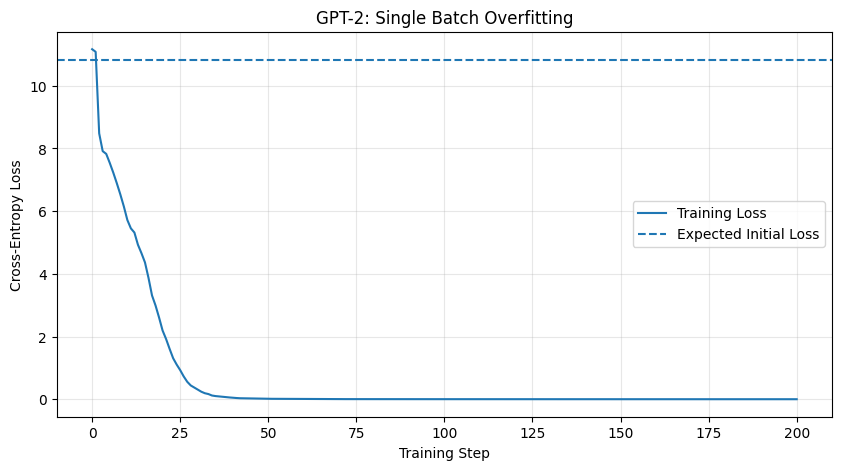


--- Memorization Test ---
Token Prediction Accuracy: 100.00%

Actual Target:
Artificial intelligence is transforming the world.
Language models learn patterns from large amounts of text.
A transformer uses attention to understand the relationships
between tokens and

Model Prediction:
Artificial intelligence is transforming the world.
Language models learn patterns from large amounts of text.
A transformer uses attention to understand the relationships
between tokens and


In [20]:

import torch
import torch.nn.functional as F
import tiktoken
import math
import matplotlib.pyplot as plt

from transformers import GPT2Config, GPT2LMHeadModel

# 1. Device Selection

device = "cpu"

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"

print("Device:", device)

torch.manual_seed(42)


# 2. Random Model Initialization

config = GPT2Config()

train_model = GPT2LMHeadModel(config)
train_model.to(device)
train_model.train()

print("Model initialized with random weights.")


# 3. Prepare Training Data

enc = tiktoken.get_encoding("gpt2")

text = """
Artificial intelligence is transforming the world.
Language models learn patterns from large amounts of text.
A transformer uses attention to understand the relationships
between tokens and predict the next token in a sequence.
Training improves the model by updating its parameters
and reducing the prediction error over time.
""" * 5

tokens = enc.encode(text)

B, T = 4, 32

buf = torch.tensor(
    tokens[:B*T+1],
    dtype=torch.long
).to(device)

x = buf[:-1].view(B, T)
y = buf[1:].view(B, T)

print("Input shape:", x.shape)
print("Target shape:", y.shape)


# 4. Calculate Loss

def calculate_loss(x, y):

    logits = train_model(x, use_cache=False).logits

    loss = F.cross_entropy(
        logits.reshape(-1, logits.size(-1)),
        y.reshape(-1)
    )

    return loss


# 5. Initial Loss Analysis

train_model.eval()

with torch.no_grad():
    initial_loss = calculate_loss(x, y).item()

expected_loss = math.log(config.vocab_size)

print("\n--- Initial Loss Analysis ---")

print(f"Expected Loss: {expected_loss:.4f}")
print(f"Actual Loss: {initial_loss:.4f}")
print(f"Difference: {abs(initial_loss - expected_loss):.4f}")


# 6. Initialize Optimizer

optimizer = torch.optim.AdamW(
    train_model.parameters(),
    lr=3e-4
)


# 7. Overfit a Single Batch

train_model.train()

num_steps = 200

loss_history = [initial_loss]

print("\n--- Training Started ---")

for step in range(num_steps):

    # Clear previous gradients
    optimizer.zero_grad()

    # Forward pass
    loss = calculate_loss(x, y)

    # Backpropagation
    loss.backward()

    # Update model weights
    optimizer.step()

    loss_history.append(loss.item())

    if (step + 1) % 10 == 0 or step == 0:

        print(
            f"Step {step+1:03d} | "
            f"Loss: {loss.item():.6f}"
        )


# 8. Final Loss Measurement

train_model.eval()

with torch.no_grad():
    final_loss = calculate_loss(x, y).item()

loss_reduction = (
    (initial_loss - final_loss) / initial_loss
) * 100

print("\n--- Final Results ---")

print(f"Expected Initial Loss: {expected_loss:.6f}")
print(f"Actual Initial Loss: {initial_loss:.6f}")
print(f"Final Loss: {final_loss:.6f}")
print(f"Loss Reduction: {loss_reduction:.2f}%")


# 9. Visualize Training Loss

plt.figure(figsize=(10, 5))

plt.plot(loss_history, label="Training Loss")

plt.axhline(
    y=expected_loss,
    linestyle="--",
    label="Expected Initial Loss"
)

plt.xlabel("Training Step")
plt.ylabel("Cross-Entropy Loss")
plt.title("GPT-2: Single Batch Overfitting")

plt.legend()
plt.grid(alpha=0.3)
plt.show()


# 10. Evaluate Memorization Accuracy

with torch.no_grad():

    logits = train_model(x, use_cache=False).logits

    predictions = logits.argmax(dim=-1)

    accuracy = (
        predictions == y
    ).float().mean().item()

print("\n--- Memorization Test ---")

print(f"Token Prediction Accuracy: {accuracy * 100:.2f}%")

print("\nActual Target:")
print(enc.decode(y[0].tolist()))

print("\nModel Prediction:")
print(enc.decode(predictions[0].tolist()))
